# **Clustering con datos faltantes**

Se abordan procedimientos para identificar grupos de observaciones en conjuntos de datos con valores faltantes. Se estudia cómo integrar la imputación múltiple con el algoritmo K-means para obtener agrupaciones a partir de diferentes versiones completas de los datos y combinar los resultados en una partición final.

Duración: 2 horas

Modalidad: Taller teórico-práctico

Herramientas: `Python` y `R`, integrados mediante `rpy2`.

## **Configuración del entorno: Python y R**

La imputación múltiple se realiza con `mice` de `R`. Las bases completadas se transfieren a `Python` para ejecutar K-means, seleccionar el número de grupo y construir el consenso. La alternativa `miclust` se ejecuta en `R` con las mismas imputaciones. `rpy2` permite intercambiar los objetos entre ambos lenguajes.

In [49]:
# Instalación de rpy2 para ejecutar código R desde Python
%pip install -q rpy2

# Activación de la extensión de R
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [50]:
# Carga de librerías de Python

# Manipulación de datos y operaciones numéricas
import numpy as np
import pandas as pd

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Estandarización y agrupamiento
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, adjusted_rand_score

# Clustering jerárquico sobre la matriz de coasociación
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import cut_tree

# ACP para representación de los grupos
from sklearn.decomposition import PCA

pd.set_option("display.width", 180)

In [51]:
# Instalación de paquetes precompilados de R necesarios para MICE y miclust
!sudo apt-get update -qq > /dev/null 2>&1
!sudo apt-get install -y -qq --no-install-recommends \
    r-cran-mice \
    r-cran-future \
    r-cran-furrr \
    r-cran-parallelly \
    r-cran-doby \
    r-cran-combinat \
    r-cran-flexclust \
    r-cran-matrixstats > /dev/null 2>&1

# Instalación de miclust desde CRAN, utilizando las dependencias precompiladas
%R install.packages("miclust", repos = "https://cloud.r-project.org", dependencies = FALSE)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/miclust_1.3.0.tar.gz'
Content type 'application/x-gzip' length 169849 bytes (165 KB)
downloaded 165 KB


The downloaded source packages are in
	‘/tmp/RtmpK6uTHV/downloaded_packages’


In [52]:
%%R
# Carga de librerías de R

# Imputación múltiple por ecuaciones encadenadas
library(mice)

# Clustering con imputación múltiple
library(miclust)

# Configuración de la impresión de resultados
options(width = 200)

## **1. Datos de calidad del agua**

El conjunto de datos ***Water Potability*** contiene 3.276 observaciones de muestras de agua y mediciones de sus características fisicoquímicas. Cada fila corresponde a una muestra; no se trata de una serie temporal.

**Fuente**: *Water Potability*. https://www.kaggle.com/datasets/adityakadiwal/water-potability

Archivo CSV para su descarga directa: https://raw.githubusercontent.com/georgefrederick/water-potability/main/water_potability.csv

### **Variables seleccionadas**

Se utilizarán nueve variables numéricas. La variable binaria `Potability` no interviene en la imputación ni en la formación de los conglomerados.

| Variable | Descripción |
|---|---|
| `ph` | Medida de acidez o alcalinidad del agua. |
| `Hardness` | Dureza del agua. |
| `Solids` | Sólidos disueltos. |
| `Chloramines` | Concentración de cloraminas. |
| `Sulfate` | Concentración de sulfatos. |
| `Conductivity` | Conductividad eléctrica. |
| `Organic_carbon` | Carbono orgánico. |
| `Trihalomethanes` | Concentración de trihalometanos. |
| `Turbidity` | Turbidez del agua. |

Los valores faltantes se concentran en `ph`, `Sulfate` y `Trihalomethanes`.

In [53]:
# Descarga de los datos
url = "https://raw.githubusercontent.com/georgefrederick/water-potability/main/water_potability.csv"
datos = pd.read_csv(url)

# Variable categórica ilustrativa
datos["Potability"] = pd.Categorical(
    datos["Potability"].map({0: "No potable", 1: "Potable"})
)

# Variables numéricas activas
datos_clust = datos.drop(columns="Potability")
datos_clust.head(10)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562


In [54]:
# Resumen descriptivo de las variables
datos_clust.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000


## **2. Exploración de valores faltantes**

La exploración de los valores faltantes permite cuantificar su frecuencia, identificar las variables afectadas y examinar los patrones de ausencia entre las observaciones.

In [55]:
# Resumen global de valores faltantes
print("Total de faltantes:", datos_clust.isna().sum().sum())
print("Porcentaje global de faltantes:",
      round(datos_clust.isna().mean().mean() * 100, 2))
print("Observaciones incompletas:", datos_clust.isna().any(axis=1).sum())
print("Observaciones completas:", datos_clust.notna().all(axis=1).sum())


Total de faltantes: 1434
Porcentaje global de faltantes: 4.86
Observaciones incompletas: 1265
Observaciones completas: 2011


In [56]:
# Descripción de los valores faltantes por variable
faltantes = pd.DataFrame({
    "Faltantes": datos_clust.isna().sum(),
    "Porcentaje (%)": datos_clust.isna().mean() * 100
})

faltantes["Porcentaje (%)"] = faltantes["Porcentaje (%)"].round(2)

faltantes


,Faltantes,Porcentaje (%)
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00


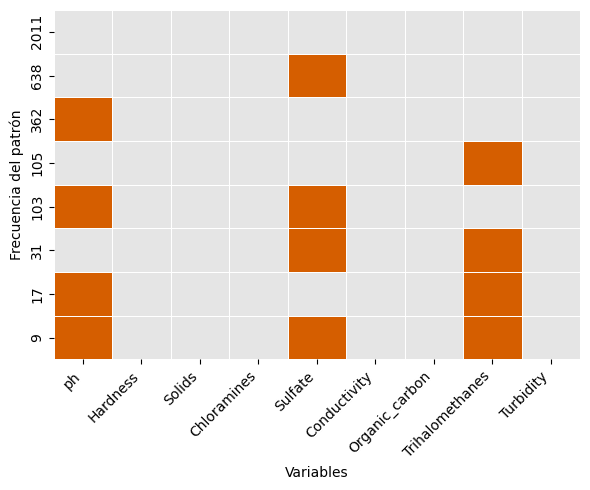

In [57]:
# Patrones conjuntos de valores observados y faltantes
patrones = (
    datos_clust.notna().astype(int)
    .value_counts()
    .rename("Frecuencia")
    .reset_index()
)

# Gráfico de patrones
plt.figure(figsize=(6, 5))
sns.heatmap(
    patrones[datos_clust.columns],
    cmap=["#D55E00", "#E5E5E5"],
    cbar=False,
    linewidths=0.5,
    yticklabels=patrones["Frecuencia"]
)

plt.xlabel("Variables")
plt.ylabel("Frecuencia del patrón")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



## **3. Imputación múltiple mediante MICE**

Se realiza un proceso de imputación múltiple mediante ecuaciones encadenadas (MICE) generando cinco $(m=5)$ bases de datos imputadas. Cada variable mumérica con faltantes es imputada por el método pmm.

In [58]:
%%R -i datos_clust
# Transferencia de las variables numéricas desde Python a R
base_r = as.data.frame(datos_clust)

# Imputación múltiple mediante PMM, con dos procesos y 30 iteraciones
imputaciones = futuremice(
  base_r,
  m = 5,
  maxit = 30,
  defaultMethod = c("pmm", "logreg", "polyreg", "polr"),
  n.core = 2,
  parallelseed = 123
)

### **Diagnóstico de las imputaciones**

Examinamos visualmente la convergencia de las imputaciones de las variables numéricas.


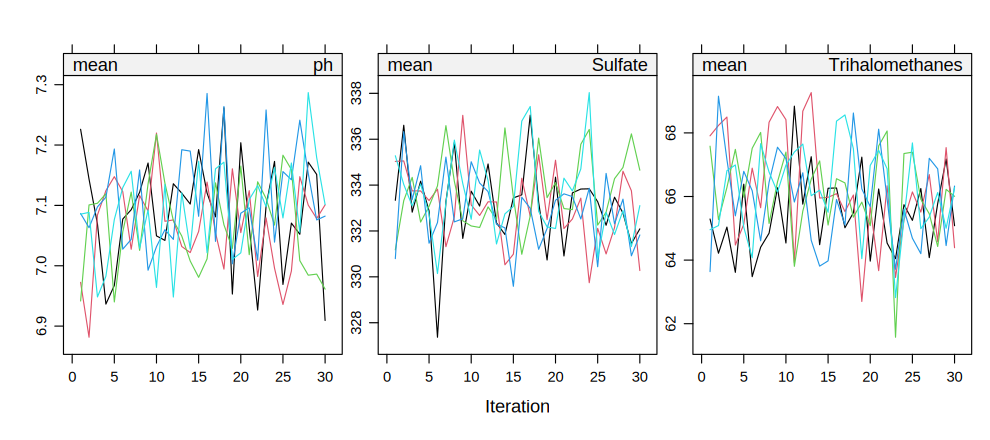

In [59]:
%%R -w 9 -h 4 -u in -r 110
# Evolución de las medias imputadas en las cadenas de MICE
plot(imputaciones, ph + Sulfate + Trihalomethanes ~ .it | .ms,
     subset = .ms == "mean", layout = c(3, 1))

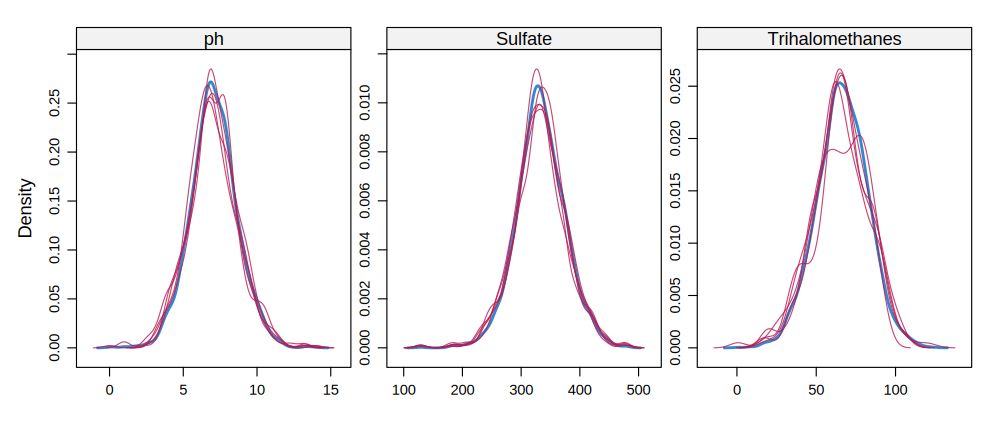

In [60]:
%%R -w 9 -h 4 -u in -r 110
# Comparación de distribuciones observadas e imputadas
print(densityplot(imputaciones, ~ ph + Sulfate + Trihalomethanes))

## **4. Algoritmo K-means**

K-means particiona las $n$ observaciones en $K$ grupos minimizando la suma de cuadrados dentro de los conglomerados:

$$
W_K=\sum_{g=1}^{K}\sum_{k:c_k=g}\lVert\mathbf z_k-\boldsymbol\mu_g\rVert^2,
$$

donde $\mathbf z_k$ contiene las variables estandarizadas de la observación $k$, $c_k$ indica su grupo y $\boldsymbol\mu_g$ es el centroide del grupo $g$. Cada base imputada se estandariza por separado, de manera que las nueve variables contribuyan en una escala comparable.

### **Selección de $K$**

Existen diferentes métricas para la determinación del número de grupos, entre ellas el índice de Calinski-Harabasz (CH), que compara la dispersión entre grupos con la dispersión dentro de los grupos:

$$
CH(K)=\frac{B_K/(K-1)}{W_K/(n-K)},
$$

donde $B_K$ y $W_K$ son, respectivamente, las sumas de cuadrados entre grupos y dentro de los grupos. Los **valores altos** indican mayor separación relativa y menor dispersión interna.

Para cada número candidato $K$, se ajusta K-means sobre las $M$ bases imputadas y se calcula el índice en cada una. Se selecciona el número que maximiza el promedio:

$$
K=\underset{K\in\mathcal K}{\arg\max}\;\frac{1}{M}\sum_{b=1}^{M}CH_K^{(b)}.
$$

La selección considera la calidad de las particiones obtenidas en las bases imputadas; la partición final de consenso se construye posteriormente.

### **Algoritmo K-means sobre cada base imputada**

Aplicamos el algoritmo de K-means sobre cada base de datos imputada.

In [61]:
%%R -o imputaciones_largas
# Transferencia a Python de las bases completadas
# Excluye la base original con valores faltantes
imputaciones_largas = complete(imputaciones, action = "long", include = FALSE)

In [62]:
# Reconstrucción de las bases imputadas en Python
numeros_imputacion = sorted(imputaciones_largas[".imp"].unique())
variables = list(datos_clust.columns)

bases_imputadas_py = [
    imputaciones_largas.loc[
        imputaciones_largas[".imp"] == b, variables
    ].reset_index(drop=True)
    for b in numeros_imputacion
]

# Estandarización independiente en cada imputación
bases_estandarizadas = [
    StandardScaler().fit_transform(base)
    for base in bases_imputadas_py
]

In [63]:
# Números de grupos candidatos y evaluación del índice Calinski-Harabasz

valores_K = range(2, 9)
resultados_ch = []

for K_candidato in valores_K:
    indices_ch = []

    for X in bases_estandarizadas:
        # K-means para un número de grupos y una base imputada
        modelo = KMeans(n_clusters=K_candidato, n_init=20, random_state=123)
        grupos = modelo.fit_predict(X)

        # Separación entre grupos respecto a la dispersión interna
        indices_ch.append(calinski_harabasz_score(X, grupos))

    # Promedio y dispersión del índice entre imputaciones
    resultados_ch.append({
        "K": K_candidato,
        "CH_promedio": np.mean(indices_ch),
        "CH_desviacion": np.std(indices_ch, ddof=1)
    })

# Número de grupos que maximiza el índice promedio
resultados_ch = pd.DataFrame(resultados_ch)
K = int(resultados_ch.loc[resultados_ch["CH_promedio"].idxmax(), "K"])

resultados_ch.round(2)

,K,CH_promedio,CH_desviacion
0,2,297.48,1.49
1,3,271.55,0.99
2,4,246.04,1.04
3,5,229.03,0.72
4,6,215.11,0.48
5,7,203.55,0.57
6,8,192.66,0.74


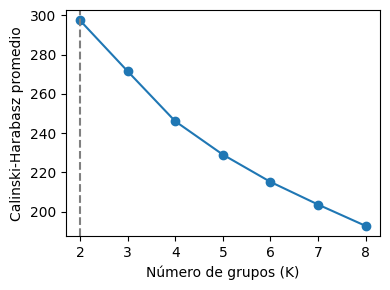

Número de grupos seleccionado: 2


In [64]:
# Comportamiento del índice Calinski-Harabasz según el número de grupos
plt.figure(figsize=(4, 3))
plt.plot(resultados_ch["K"], resultados_ch["CH_promedio"], marker="o")
plt.axvline(K, linestyle="--", color="gray")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Calinski-Harabasz promedio")
plt.xticks(list(valores_K))
plt.tight_layout()
plt.show()

print("Número de grupos seleccionado:", K)

In [65]:
# K-means definitivo sobre cada base imputada, con el K seleccionado
particiones = []

for X in bases_estandarizadas:
    modelo = KMeans(n_clusters=K, n_init=20, random_state=123)
    particiones.append(modelo.fit_predict(X))

# Cada fila corresponde a una imputación y cada columna a una observación
etiquetas = np.asarray(particiones, dtype=np.int32)

# Tamaños de los grupos en cada imputación
pd.DataFrame([
    {"Imputación": b, **{f"Grupo {g+1}": int(np.sum(p == g)) for g in range(K)}}
    for b, p in zip(numeros_imputacion, particiones)
])

,Imputación,Grupo 1,Grupo 2
0,1,1498,1778
1,2,1468,1808
2,3,1866,1410
3,4,1863,1413
4,5,1869,1407


## **5. Consenso mediante coasociación**

La imputación múltiple produce $m$ particiones que pueden diferir en las asignaciones individuales. La matriz de coasociación cuantifica con qué frecuencia dos observaciones quedan en el mismo grupo a través de las imputaciones:

$$
C_{kl}=\frac{1}{m}\sum_{b=1}^{m}I(c_k^{(b)}=c_l^{(b)}),
$$

donde $c_k^{(b)}$ es la asignación de la observación $k$ en la imputación $b$ e $I(\cdot)$ es la función indicadora. Así, $C_{kl}=1$ significa que las dos observaciones quedaron juntas en todas las imputaciones, mientras que $C_{kl}=0$ indica que nunca compartieron grupo. La matriz de disimilitudes se define por $D_{kl}=1-C_{kl}$.

La partición de consenso se obtiene mediante clustering jerárquico aglomerativo con **enlace completo** (*complete linkage*). La disimilitud entre dos grupos $G$ y $H$ es

$$
D(G,H)=\max_{k\in G,\,l\in H}D_{kl}.
$$

En cada paso se fusionan los dos grupos cuya mayor disimilitud entre sus integrantes es la menor. Este criterio favorece agrupaciones compactas en términos de coasociación. Se utiliza enlace completo porque opera directamente sobre la matriz de disimilitudes de consenso. Finalmente, se corta el dendrograma para obtener el mismo $K$ seleccionado mediante Calinski-Harabasz.

In [66]:
# Número de particiones y de observaciones
m, n = etiquetas.shape

# Frecuencia de pertenencia conjunta para cada pareja de observaciones
conteos = np.zeros((n, n), dtype=np.uint16)

for particion in etiquetas:
    # Comparación de los grupos asignados a todas las parejas
    mismo_grupo = particion[:, None] == particion[None, :]

    # Acumulación de las coincidencias entre imputaciones
    conteos += mismo_grupo

# Coasociación: proporción de imputaciones en las que las parejas comparten grupo
coasociacion = conteos.astype(np.float32) / m

# Disimilitud: menor valor cuando existe mayor frecuencia de coagrupamiento
disimilitud = 1.0 - coasociacion
np.fill_diagonal(disimilitud, 0.0)

# Pares distintos, sin contar dos veces los elementos simétricos
triangulo = np.triu_indices(n, k=1)

# Resumen descriptivo de la coasociación entre observaciones
pd.Series(coasociacion[triangulo], name="Coasociación").describe().round(3)

,Coasociación
count,5364450.000
mean,0.507
std,0.393
min,0.000
25%,0.000
50%,0.600
75%,1.000
max,1.000


In [67]:
# Conversión de la matriz de disimilitudes a su forma condensada
# Se almacenan únicamente las disimilitudes entre parejas distintas
condensada = squareform(disimilitud, checks=False)

# Clustering jerárquico aglomerativo mediante enlace completo
jerarquia = linkage(condensada, method="complete")

# Corte del dendrograma para obtener exactamente K grupos
consenso = cut_tree(jerarquia, n_clusters=K).ravel() + 1

# Tamaños de los grupos en la partición de consenso
pd.Series(consenso, name="Grupo").value_counts().sort_index().rename("Muestras")

,Muestras
Grupo,
1,1487
2,1789


### **Concordancia entre las particiones y el consenso**

El índice de Rand ajustado (ARI) compara dos particiones de las mismas observaciones mediante las parejas que quedan juntas o separadas en cada una. Corrige la concordancia esperada bajo un modelo de asignaciones aleatorias con tamaños de grupos fijos:

$$
ARI=\frac{RI-E(RI)}{\max(RI)-E(RI)}.
$$

Un valor de 1 indica concordancia perfecta, los valores próximos a 0 corresponden a concordancia comparable a la esperada por azar y los negativos indican una concordancia inferior. Se calcula el ARI entre cada partición imputada y el consenso. Estos valores describen la coherencia interna de las particiones, ya que el consenso se construye con ellas; no constituyen una validación independiente.

In [68]:
# Concordancia de cada partición imputada con el consenso
pd.DataFrame({
    "Imputación": numeros_imputacion,
    "ARI respecto al consenso": [
        adjusted_rand_score(particion, consenso)
        for particion in particiones
    ]
}).round(3)

,Imputación,ARI respecto al consenso
0,1,0.676
1,2,0.608
2,3,0.399
3,4,0.510
4,5,0.588


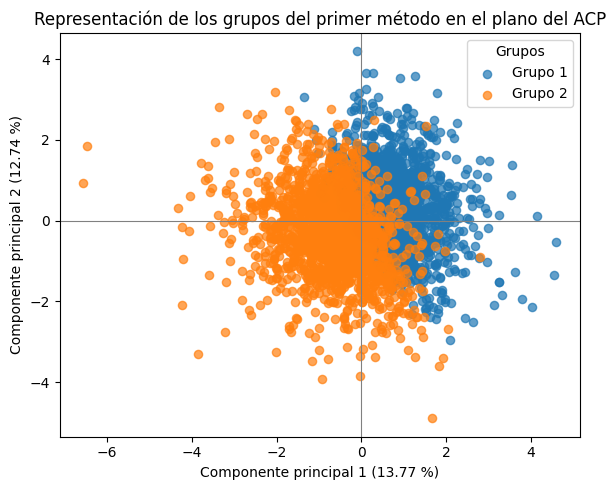

In [69]:
# Representación de los grupos en el primer plano principal de un ACP

from sklearn.decomposition import PCA

# Se utilizará la primera base imputada
X_pca = bases_estandarizadas[0]

# Ajuste del ACP conservando dos componentes principales
acp = PCA(n_components=2)
componentes = acp.fit_transform(X_pca)

# Base para graficar
grafico_acp = pd.DataFrame({
    "CP1": componentes[:, 0],
    "CP2": componentes[:, 1],
    "Grupo": consenso.astype(str)
})

# Porcentaje de varianza explicada por las dos primeras componentes
var_exp = acp.explained_variance_ratio_ * 100

# Gráfico de dispersión
plt.figure(figsize=(6, 5))

for grupo in sorted(grafico_acp["Grupo"].unique(), key=int):
    datos_grupo = grafico_acp[grafico_acp["Grupo"] == grupo]
    plt.scatter(
        datos_grupo["CP1"],
        datos_grupo["CP2"],
        label=f"Grupo {grupo}",
        alpha=0.7,
        s=35
    )

plt.axhline(0, linewidth=0.8, color="gray")
plt.axvline(0, linewidth=0.8, color="gray")

plt.xlabel(f"Componente principal 1 ({var_exp[0]:.2f} %)")
plt.ylabel(f"Componente principal 2 ({var_exp[1]:.2f} %)")
plt.title("Representación de los grupos del primer método en el plano del ACP")
plt.legend(title="Grupos")
plt.tight_layout()
plt.show()

## **6. Algoritmo `miclust`**

`miclust` integra el clustering de múltiples bases imputadas mediante un procedimiento basado en K-means. Para cada base completada evalúa diferentes números de grupos y selecciona el más apropiado mediante el criterio CritCF, que utiliza las inercias dentro y entre grupos e incorpora una penalización por complejidad:

$$
CritCF=\left(\frac{2p}{2p+1}\frac{1}{1+W/B}\right)^{\frac{1+\log_2(K+1)}{1+\log_2(p+1)}},
$$

donde $p$ es el número de variables, $K$ el número de grupos y $W$ y $B$ las inercias dentro y entre grupos. Se prefieren valores altos de CritCF. `miclust` combina las soluciones de las imputaciones para determinar asignaciones finales y estimar la frecuencia relativa de asignación individual a los grupos.

La asignación se realiza mediante las frecuencias relativas de pertenencia a cada grupo, después de armonizar las etiquetas de los conglomerados. Para cada observación $k$, se calcula su frecuencia relativa de asignación al grupo $g$:
$$
p_{kg}=\frac{1}{m}\sum_{b=1}^{m}
I\left(c_k^{(b)}=g\right),
$$
donde $c_k^{(b)}$ representa la asignación de la observación \(k\) en la imputación \(b\), después de armonizar las etiquetas. La asignación final se determina seleccionando el grupo con mayor frecuencia de pertenencia:
$$
c_k^*=\underset{g=1,\ldots,K}{\arg\max}\;p_{kg}
$$

Se examinan los mismos valores candidatos de $K$ que antes, con las nueve variables y sin selección adicional de variables (`search = "none"`). La función `getdata()` organiza la base incompleta y las cinco bases imputadas para que `miclust()` las analice.

In [70]:
%%R
# Bases completadas
bases_imputadas_r = complete(imputaciones, action = "all")

# Preparación de las bases imputadas para miclust (estandariza)
base_miclust = getdata(c(list(base_r), bases_imputadas_r))

# Clustering en cada imputación y selección de K mediante CritCF
resultado_miclust = miclust(
  data = base_miclust,
  method = "kmeans",
  search = "none",
  ks = 2:8,
  distance = "euclidean",
  centpos = "means",
  initcl = "rand",
  seed = 123,
  verbose = FALSE
)

# Número de grupos elegido por miclust
resultado_miclust$kfin

[1] 3


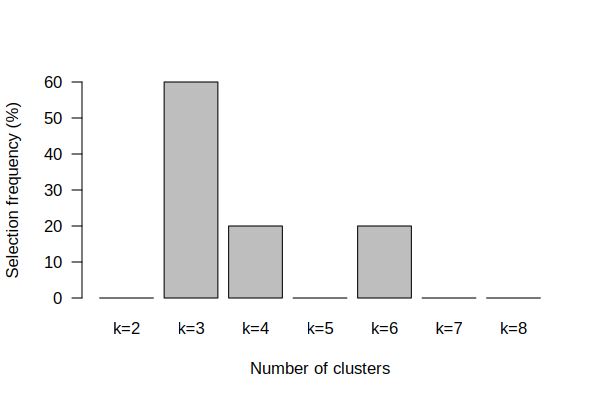

In [71]:
%%R -w 6 -h 4 -u in -r 100

# Frecuencia de selección del número de grupos

# Porcentaje de imputaciones que seleccionan cada K mediante CritCF
plot(resultado_miclust, metric = "nclfreq")

### **Partición final y probabilidades de pertenencia**

La función `summary()` integra las asignaciones obtenidas en las imputaciones. Su resultado contiene la partición final (`cluster`) y una matriz de probabilidades empíricas de asignación (`classmatrix`). Cada fila de esa matriz corresponde a una observación y cada columna a un grupo; sus valores reflejan la variación de las asignaciones entre imputaciones. Se resumen los tamaños de los grupos y las probabilidades, sin mostrar las bases imputadas.

In [72]:
%%R
# Partición final correspondiente al K seleccionado por miclust
resumen_miclust = summary(resultado_miclust)

# Número de observaciones en cada grupo final
resultado_tamanos = as.data.frame(table(resumen_miclust$cluster))
names(resultado_tamanos) = c("Grupo", "Muestras")
resultado_tamanos

  Grupo Muestras
1     1     1120
2     2     1217
3     3      939


In [73]:
%%R
# Resumen de las probabilidades empíricas de pertenencia por grupo
probabilidades = as.data.frame(resumen_miclust$classmatrix)
data.frame(
  Grupo = colnames(probabilidades),
  Probabilidad_media = round(colMeans(probabilidades), 3)
)

   Grupo Probabilidad_media
C1    C1              0.339
C2    C2              0.371
C3    C3              0.291


In [74]:
%%R -o grupos_miclust
# Asignación final de las observaciones según miclust
# para representación ACP
grupos_miclust = summary(resultado_miclust)$cluster

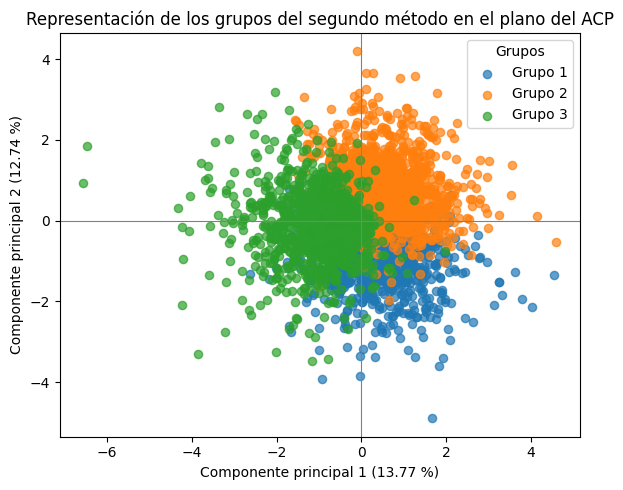

In [75]:
# Representación de los grupos en el primer plano principal

# Se utilizará la primera base imputada estandarizada
X_pca = bases_estandarizadas[0]

# Ajuste del ACP conservando dos componentes principales
acp = PCA(n_components=2)
componentes = acp.fit_transform(X_pca)

# Conversión de las asignaciones finales de miclust a vector unidimensional
grupos_miclust = np.array(grupos_miclust).ravel()

# Base de datos para la representación gráfica
grafico_acp_miclust = pd.DataFrame({
    "CP1": componentes[:, 0],
    "CP2": componentes[:, 1],
    "Grupo": grupos_miclust.astype(str)
})

# Porcentaje de varianza explicada por las dos primeras componentes
var_exp = acp.explained_variance_ratio_ * 100

# Gráfico de dispersión
plt.figure(figsize=(6, 5))

for grupo in sorted(grafico_acp_miclust["Grupo"].unique(), key=int):
    datos_grupo = grafico_acp_miclust[grafico_acp_miclust["Grupo"] == grupo]
    plt.scatter(
        datos_grupo["CP1"],
        datos_grupo["CP2"],
        label=f"Grupo {grupo}",
        alpha=0.7,
        s=35
    )

plt.axhline(0, linewidth=0.8, color="gray")
plt.axvline(0, linewidth=0.8, color="gray")

plt.xlabel(f"Componente principal 1 ({var_exp[0]:.2f} %)")
plt.ylabel(f"Componente principal 2 ({var_exp[1]:.2f} %)")
plt.title("Representación de los grupos del segundo método en el plano del ACP")
plt.legend(title="Grupos")
plt.tight_layout()
plt.show()

## **Comparación del método de concenso y el algoritmo 'MICLUST'**

Para comparar los resultados de los dos procedimientos de clustering, se evaluarán las particiones finales mediante los índices de *Calinski-Harabasz*, *silueta* y *Davies-Bouldin*. Estos criterios permiten examinar la cohesión interna y la separación entre los grupos identificados.

In [76]:
# Evaluación de las particiones finales mediante tres índices

from sklearn.metrics import (
    calinski_harabasz_score, # maximizar
    silhouette_score,        # maximizar
    davies_bouldin_score     # miximizar
)

# Particiones finales de ambos procedimientos
particiones_finales = {
    "Consenso": np.asarray(consenso).ravel(),
    "MICLUST": np.asarray(grupos_miclust).ravel()
}

# Evaluación sobre las bases imputadas
resultados = []

for metodo, grupos in particiones_finales.items():
    for b, X in zip(numeros_imputacion, bases_estandarizadas):

        resultados.append({
            "Método": metodo,
            "Imputación": b,
            "Calinski-Harabasz": calinski_harabasz_score(X, grupos),
            "Silueta": silhouette_score(
                X, grupos, sample_size=1000, random_state=123
            ),
            "Davies-Bouldin": davies_bouldin_score(X, grupos)
        })

# Resultados individuales
tabla_indices = pd.DataFrame(resultados)

# Promedios de los índices entre imputaciones
promedios = (
    tabla_indices
    .groupby("Método", as_index=False)
    [["Calinski-Harabasz", "Silueta", "Davies-Bouldin"]]
    .mean()
)

promedios["Imputación"] = "Promedio"

# Tabla final de comparación
tabla_indices = pd.concat(
    [tabla_indices, promedios],
    ignore_index=True
)

tabla_indices[
    ["Método", "Imputación", "Calinski-Harabasz", "Silueta", "Davies-Bouldin"]
].round(3)

,Método,Imputación,Calinski-Harabasz,Silueta,Davies-Bouldin
0,Consenso,1,266.096,0.068,3.353
1,Consenso,2,261.304,0.068,3.383
2,Consenso,3,245.088,0.062,3.494
3,Consenso,4,249.179,0.066,3.464
4,Consenso,5,258.930,0.067,3.399
5,MICLUST,1,262.181,0.071,2.832
6,MICLUST,2,264.694,0.072,2.826
7,MICLUST,3,262.895,0.071,2.831
8,MICLUST,4,263.228,0.071,2.830
9,MICLUST,5,260.633,0.071,2.840
